# Práctica — Leyes de potencia y periodicidades en hipnogramas

**Licenciatura en Inteligencia Artificial**

Los archivos CSV que se comparten contienen hipnogramas de registros de aproximadamente **8 horas** de sueño. Cada fila corresponde a un **segmento de 30 segundos**. La primera columna es el número de segmento y la segunda es la etapa de sueño codificada de la siguiente manera:

| Código | Etapa |
|---|---|
| 0 | Vigilia (W) |
| 1 | Etapa 1 |
| 2 | Etapa 2 |
| 3 | Etapa 3 |
| 4 | Etapa 4 |
| 5 | REM (MOR) |
| 6 | Movimiento |
| 7 | Sin clasificar |

> **Tiempo-vida (lifetime):** duración de una racha consecutiva de un mismo símbolo. Por ejemplo, en la secuencia `... 2 2 2 5 ...` la etapa 2 tiene un tiempo-vida de 3 segmentos = 90 segundos. Todo el análisis de esta práctica se construye sobre esta magnitud.


## Objetivos

Al terminar esta práctica deberás ser capaz de:

1. Generar los gráficos **tiempo-vida de las fases de sueño vs. frecuencia** (en escala log-log) de cada hipnograma.
2. Estimar el exponente de la ley de potencia $\alpha$ mediante **regresión por mínimos cuadrados (OLS)** sobre el log-log (tiempo-vida vs. frecuencia), reportando **p-valor y $R^2$**; y contrastar con el **método de Clauset** (máxima verosimilitud + estimación de $x_{\min}$ + p-valor por Monte Carlo), usando el paquete `powerlaw`. Estimar el p-valor en ambos casos **e interpretarlo**.
3. Comparar ambos métodos y **justificar cuál es mejor**.
4. Repetir el análisis completo (puntos 1, 2 y 3) con **bigramas, trigramas, ..., 7-gramas**.
5. Concluir **qué $n$-grama se parece más a una ley de potencia**.
6. Elegir **una medida de teoría de la información** (entropía marginal, entropía conjunta, entropía condicional o información mutua, de manera univariada) para buscar **periodicidades** en la dinámica de cada registro.
7. Generar los gráficos de la medida elegida **en función del retardo $\tau$** e interpretar si existe evidencia de comportamiento periódico.


## 6. Teoría de la información: buscando periodicidades

**Elige UNA** de las siguientes medidas y justifica tu elección:

| Medida | Definición | Qué revela |
|---|---|---|
| Entropía marginal | $H(X) = -\sum_x p(x)\log_2 p(x)$ | Uniformidad del histograma de etapas |
| Entropía conjunta | $H(X_t, X_{t+\tau})$ | Incertidumbre conjunta a retardo $\tau$ |
| Entropía condicional | $H(X_{t+\tau}\mid X_t) = H(X_t,X_{t+\tau}) - H(X_t)$ | Incertidumbre residual del futuro dado el presente |
| Información mutua | $I(X_t;X_{t+\tau}) = H(X_t)+H(X_{t+\tau})-H(X_t,X_{t+\tau})$ | Redundancia compartida; **picos en los retardos periódicos** |

La idea: si la dinámica tiene un **período $T$**, muestrear la señal cada $\tau = T, 2T, \dots$ la alinea consigo misma. Esperamos entonces: **mínimos** en $H(\tau)$ (menor sorpresa) o **máximos** en $I(\tau)$ (máxima dependencia) en esos retardos. En el sueño, el candidato fisiológico es el **ciclo ultradiano de ~90 min ≈ 180 segmentos** (≈ 1.5 h).

## 7. Interpretación de los resultados

1. **Describe la forma de la curva**: ¿hay mínimos locales de la entropía (o máximos de la información mutua)? ¿En qué valores de $\tau$ aparecen?
2. **Relación con la fisiología**: ¿coinciden con el ciclo de ~90 min? ¿Se observan armónicos ($\tau \approx 3$ h)?
3. **Comparación entre registros**: ¿el patrón es consistente entre archivos?
4. **Artefactos**: discute el efecto de las etapas 6 (Movimiento) y 7 (Sin clasificar). Opcional: repite la figura **excluyéndolas** (reemplázalas o filtra la señal) y compara.
5. **Conclusión**: ¿hay evidencia estadística/estructural de comportamiento periódico en la dinámica univariada de los hipnogramas? Argumenta a favor o en contra, y conecta con lo encontrado en el punto 5 (¿cambia la respuesta con el $n$-grama elegido?).

---

## Entregables
- Notebook ejecutado (código + salidas) con las figuras de los puntos 1, 4 y 7.
- Tablas resumen de los puntos 2 y 4 (con **interpretación escrita** de p-valores y $R^2$).
- Discusión de los puntos 3, 5 y 7 en celdas markdown.



## Rúbrica TENTATIVA (100 pts)
| Criterio | Pts |
|---|---|
| Gráficos log-log correctos y completos (pts. 1) | 15 |
| Estimación e interpretación OLS + Clauset (pt. 2) | 25 |
| Comparación y justificación de métodos (pt. 3) | 15 |
| Análisis n-gramas + tabla + conclusión (pts. 4–5) | 20 |
| Medida de información, figuras e interpretación (pts. 6–7) | 15 |
| Calidad del notebook y del informe | 10 |

# Práctica

In [21]:
#Librerias
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [22]:
#Procesamiento de los datos
#Libreria
df = pd.read_csv('scoring_combined.csv')
hipnogramas = {
    nombre: grupo['scor_clean'].reset_index(drop=True)
    for nombre, grupo in df.groupby('name')
}
print(f"Total de hipnogramas: {len(hipnogramas)}")
print(f"Sujetos disponibles: {list(hipnogramas.keys())[:5]} ...")

Total de hipnogramas: 29
Sujetos disponibles: ['Scoring_AA_1', 'Scoring_AG_1', 'Scoring_AQ_1', 'Scoring_AR_1', 'Scoring_AR_2'] ...


In [23]:
#Verificacion del lifetime
for sujeto, serie_hipnograma in hipnogramas.items():
    num_epocas = len(serie_hipnograma)
    duracion_horas = (num_epocas * 30) / 3600
    print(f"Sujeto: {sujeto} | Épocas: {num_epocas} | Duración: {duracion_horas:.2f} h")
    
    # Aquí irá la función de extracción de lifetimes L para este hipnograma específico

Sujeto: Scoring_AA_1 | Épocas: 858 | Duración: 7.15 h
Sujeto: Scoring_AG_1 | Épocas: 920 | Duración: 7.67 h
Sujeto: Scoring_AQ_1 | Épocas: 864 | Duración: 7.20 h
Sujeto: Scoring_AR_1 | Épocas: 1061 | Duración: 8.84 h
Sujeto: Scoring_AR_2 | Épocas: 977 | Duración: 8.14 h
Sujeto: Scoring_AV_1 | Épocas: 798 | Duración: 6.65 h
Sujeto: Scoring_BP_1 | Épocas: 805 | Duración: 6.71 h
Sujeto: Scoring_CG_i | Épocas: 824 | Duración: 6.87 h
Sujeto: Scoring_DG_2 | Épocas: 1055 | Duración: 8.79 h
Sujeto: Scoring_DJ_i | Épocas: 870 | Duración: 7.25 h
Sujeto: Scoring_ED_i | Épocas: 899 | Duración: 7.49 h
Sujeto: Scoring_EL_1 | Épocas: 1219 | Duración: 10.16 h
Sujeto: Scoring_EL_2 | Épocas: 947 | Duración: 7.89 h
Sujeto: Scoring_EP_1 | Épocas: 906 | Duración: 7.55 h
Sujeto: Scoring_GA_2 | Épocas: 1023 | Duración: 8.53 h
Sujeto: Scoring_IN_1 | Épocas: 1109 | Duración: 9.24 h
Sujeto: Scoring_IN_2 | Épocas: 981 | Duración: 8.18 h
Sujeto: Scoring_JM_i | Épocas: 797 | Duración: 6.64 h
Sujeto: Scoring_JS_2 |

In [24]:
hipnogramas_np = {
    nombre: grupo['scor_clean'].to_numpy()
    for nombre, grupo in df.groupby('name')
}

## Lifetime de las fases de sueño vs frecuencia

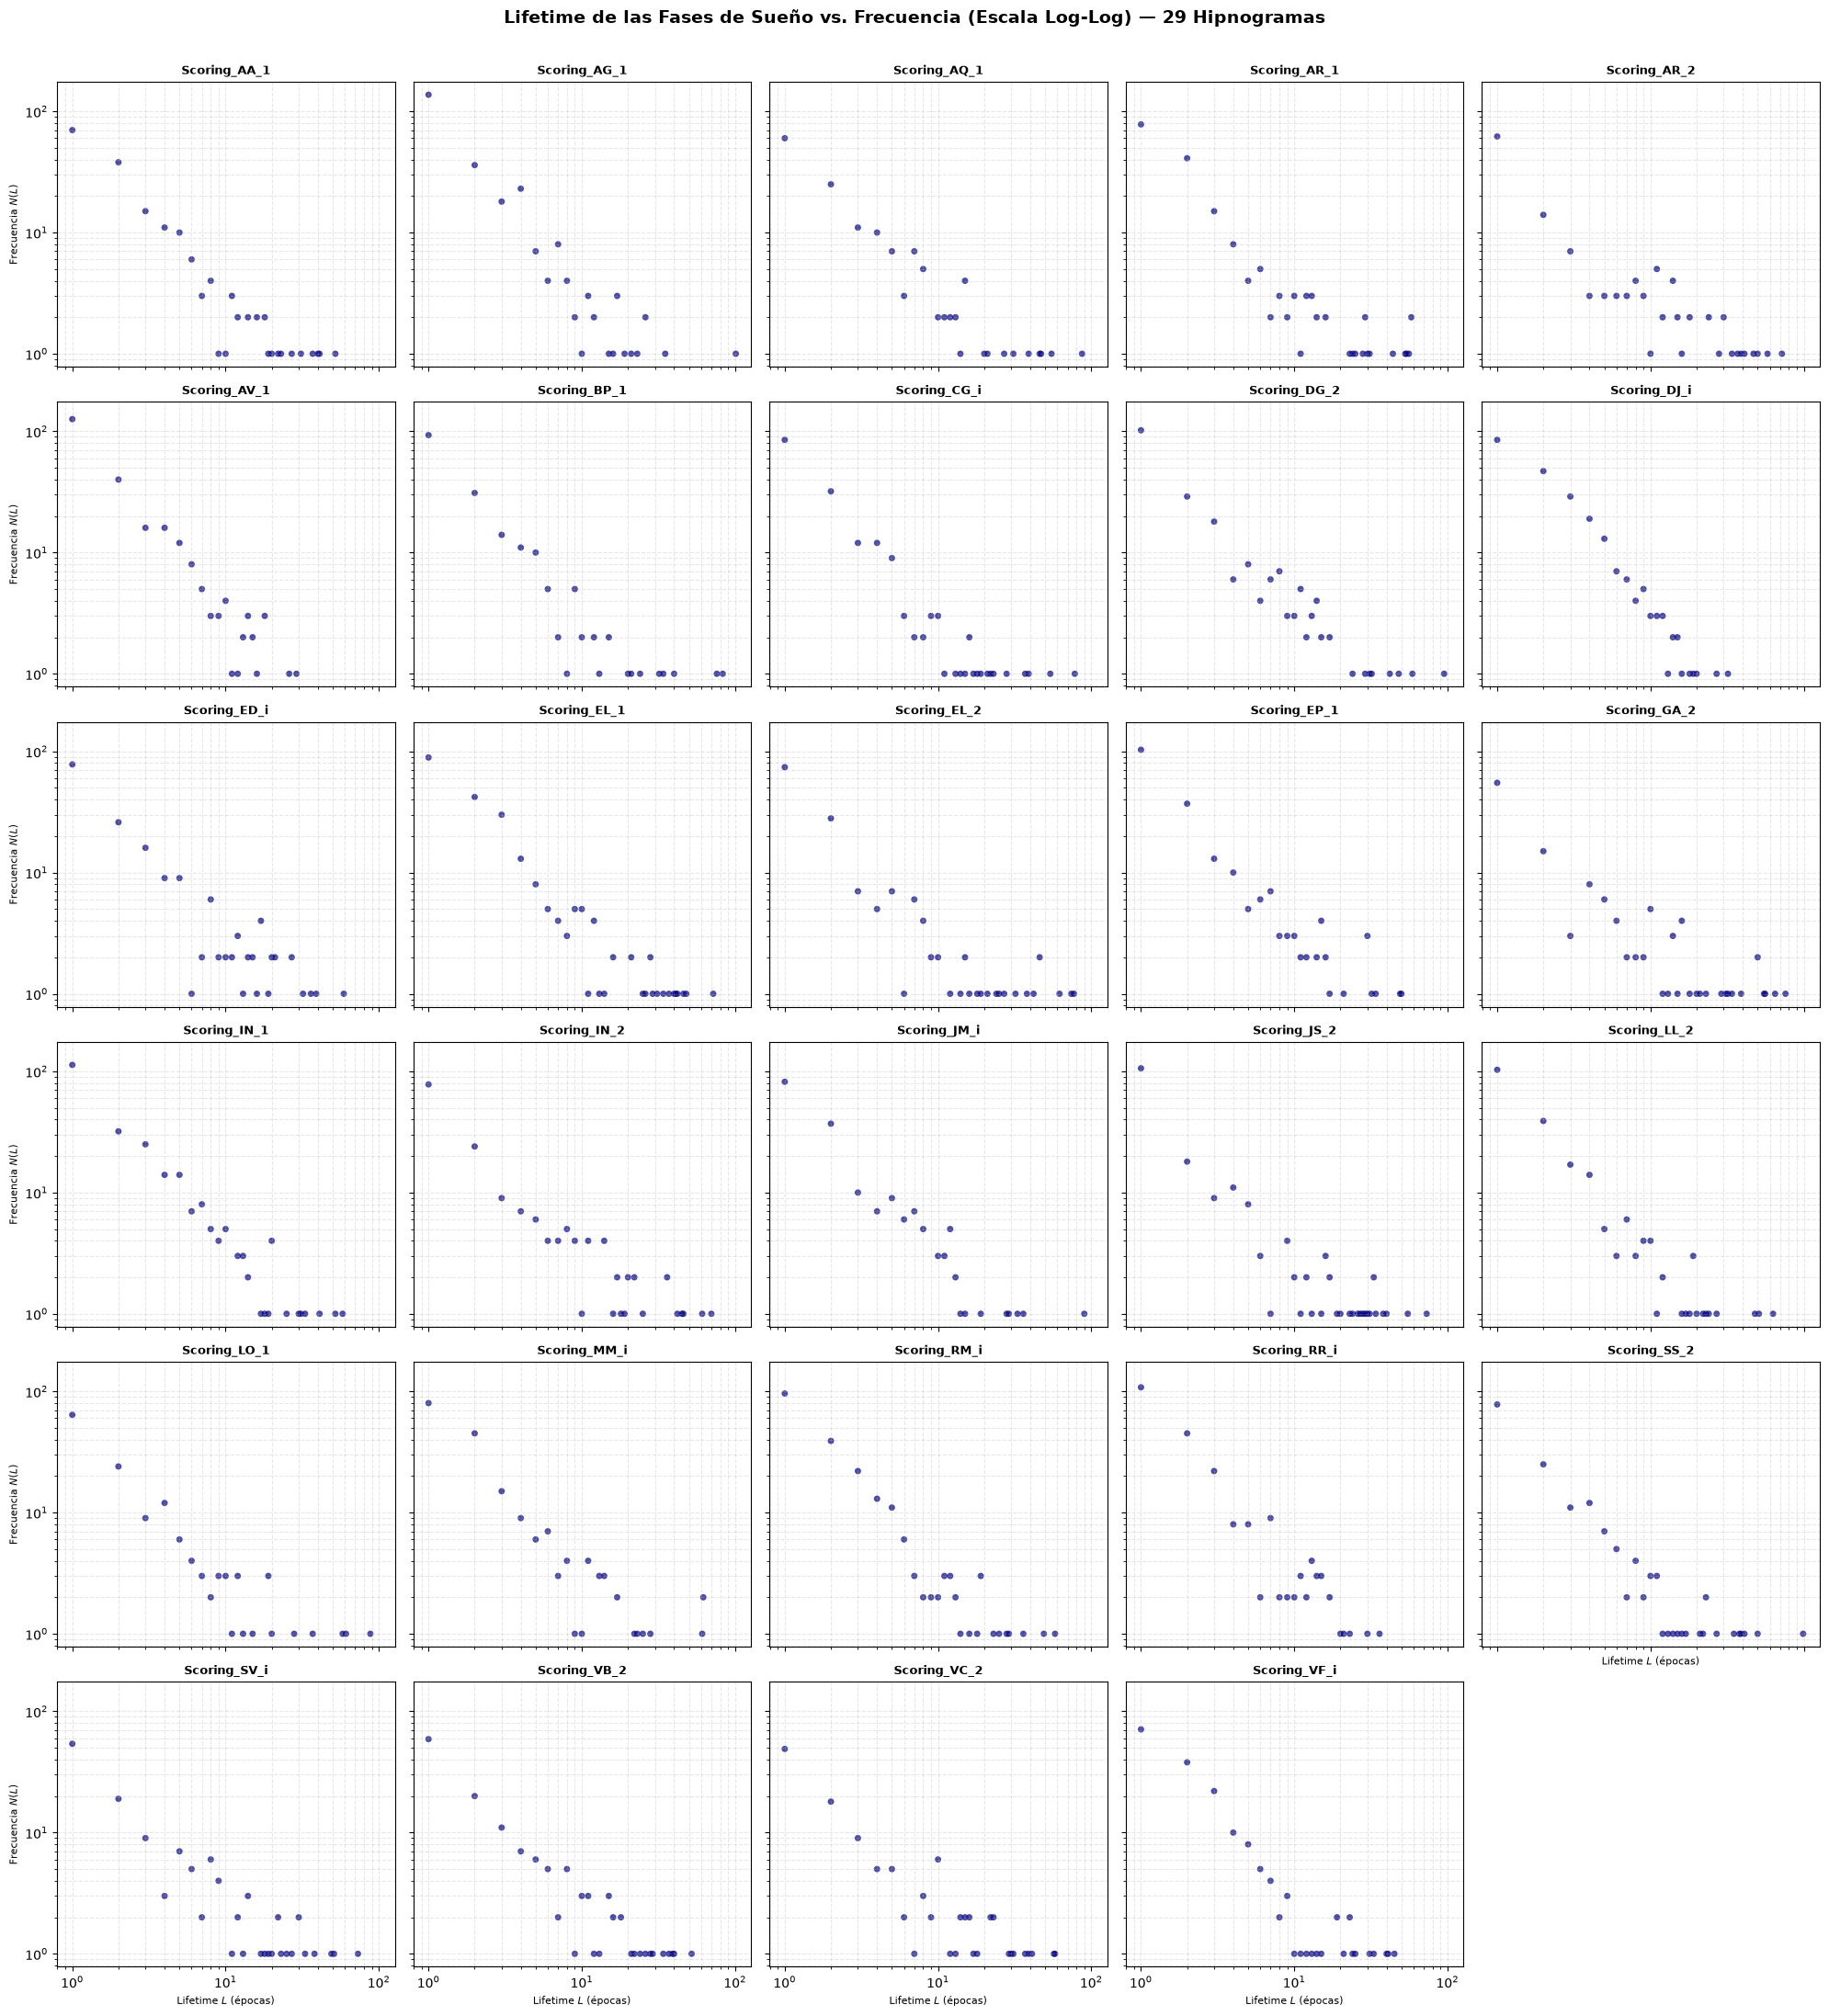

In [25]:
def calcular_lifetimes(sequence: np.ndarray) -> np.ndarray:
    """
    Calcula la duración (en número de épocas) de cada racha ininterrumpida
    de un mismo estado en la secuencia del hipnograma.
    """
    if len(sequence) == 0:
        return np.array([])
    # Identificar puntos de cambio entre épocas
    cambios = np.diff(sequence) != 0
    indices = np.concatenate(([0], np.where(cambios)[0] + 1, [len(sequence)]))
    lifetimes = np.diff(indices)
    return lifetimes

# Generación del panel de 29 hipnogramas en escala log-log
fig, axes = plt.subplots(6, 5, figsize=(20, 22), sharex=True, sharey=True)
axes = axes.flatten()

sujetos = list(hipnogramas.keys())

for i, sujeto in enumerate(sujetos):
    ax = axes[i]
    lfts = calcular_lifetimes(hipnogramas[sujeto])
    
    # Conteo de frecuencias de cada lifetime
    valores, conteos = np.unique(lfts, return_counts=True)
    
    ax.scatter(valores, conteos, color='navy', alpha=0.7, edgecolors='none', s=25)
    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.set_title(sujeto, fontsize=9, fontweight='bold')
    ax.grid(True, which="both", ls="--", alpha=0.3)
    if i % 5 == 0:
        ax.set_ylabel('Frecuencia $N(L)$', fontsize=8)
    if i >= 24:
        ax.set_xlabel('Lifetime $L$ (épocas)', fontsize=8)

# Eliminar el subgráfico 30 sobrante
if len(sujetos) < len(axes):
    for j in range(len(sujetos), len(axes)):
        fig.delaxes(axes[j])

plt.suptitle('Lifetime de las Fases de Sueño vs. Frecuencia (Escala Log-Log) — 29 Hipnogramas', fontsize=14, fontweight='bold', y=0.995)
plt.tight_layout(rect=[0, 0, 1, 0.99])
plt.savefig('lifetimes_29_hipnogramas.png', dpi=200)
plt.show()